# pandasで作成したデータフレームからグラフ表示と基本統計量を求めよう

7.4章でマージしたデータフレームから、カテゴリーごとの出現回数を棒グラフで表示し、商品番号ごとに注文数の基本統計量を求める。

## Step1. 必要なライブラリをインポートする

Google Colaboratory では、japanize_matplotlib を使う前にインストールする。

In [1]:
!pip install japanize-matplotlib

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import japanize_matplotlib

## データフレームを用意する

`sample_pandas_6.csv` と `category.csv` を読み込み、7.4章と同じように商品番号でマージする。

In [3]:
# 7.4章で作成したデータフレームを用意する
df = pd.read_csv('sample_pandas_6.csv')
category_df = pd.read_csv('category.csv')
df = pd.merge(df, category_df[['商品番号', 'カテゴリー']], how='inner', on='商品番号')
df.head()

,発注日,商品番号,商品名,単価,在庫,注文数,カテゴリー
0,2016-03-06,YY4HAAZR,商品サンプル YY4HAAZR,780,20,24,弁当
1,2015-03-27,Z4WOOIYV,商品サンプル Z4WOOIYV,90,45,12,飲料水
2,2017-05-31,YY4HAAZR,商品サンプル YY4HAAZR,780,10,0,弁当
3,2022-10-26,1QJFO8QY,商品サンプル 1QJFO8QY,600,5,24,弁当
4,2016-06-10,1QJFO8QY,商品サンプル 1QJFO8QY,600,40,24,弁当


## Step2・Step3. カテゴリーの出現回数を棒グラフで表示する

`value_counts()` でカテゴリー列の要素ごとの出現回数を数え、その結果（シリーズ）に `plot(kind='bar')` を続けて棒グラフにする。

In [4]:
# カテゴリー列の要素ごとの出現回数
df['カテゴリー'].value_counts()

カテゴリー
弁当       49
菓子類      38
飲料水      36
デザート     30
雑貨       27
図書・新聞    20
Name: count, dtype: int64

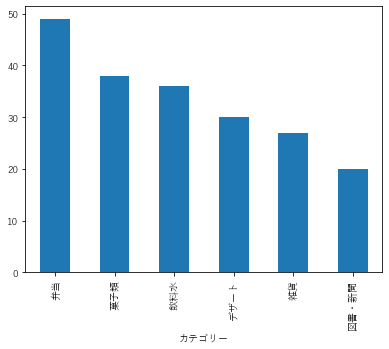

In [5]:
# Step2. 出現回数を数えて棒グラフにする
df['カテゴリー'].value_counts().plot(kind='bar')

# Step3. グラフを表示する
plt.show()

## Step4. 商品番号ごとに注文数の基本統計量を求める

`groupby('商品番号')` で商品番号ごとにまとめ、注文数列に `describe()` を使う。

In [6]:
# Step4. 商品番号ごとに注文数の基本統計量を求める
df.groupby('商品番号')['注文数'].describe()

,count,mean,std,min,25%,50%,75%,max
商品番号,,,,,,,,
1QJFO8QY,32.0,35.250000,18.461818,0.0,24.0,36.0,49.5,60.0
2HSTCDWM,20.0,29.400000,21.137146,0.0,12.0,27.0,48.0,60.0
48XMJXKO,10.0,21.600000,13.326665,0.0,13.5,21.0,30.0,42.0
8T7D5DQA,21.0,25.142857,18.260027,0.0,12.0,36.0,42.0,54.0
MESUDVWQ,17.0,43.764706,18.219253,0.0,42.0,48.0,54.0,60.0
QRMOGNUU,27.0,33.111111,16.588535,6.0,21.0,36.0,48.0,60.0
S6RE8W6X,20.0,33.300000,21.631118,0.0,12.0,39.0,54.0,60.0
X0ZE2ZMY,14.0,21.857143,21.901377,0.0,1.5,15.0,39.0,60.0
YY4HAAZR,17.0,31.764706,18.095336,0.0,18.0,30.0,42.0,60.0
